# Fitting Forward mTRF

In [1]:
### Importing the mTRF package

from mtrf_modified.model import TRF
from mtrf_modified.stats import nested_crossval

# Bialas et al., (2023). mTRFpy: A Python package for temporal response function analysis. Journal of Open Source Software, 8(89), 5657, https://doi.org/10.21105/joss.05657

### Importing other packages

# 1. Core
import math
import pickle
import pathlib
import os
import ptitprince as pt
import random
from scipy.stats import zscore
from pathlib import Path

# 2. Data Science
import numpy as np
import pandas as pd
import scipy
import statsmodels.formula.api as smf
import statsmodels.api as sm

# 3. Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Brain Core
import mne

# 5. Custom package
import movement_data_analysis_functions as md

In [2]:
base_folder = Path.cwd()

# 1. Setup

In [3]:
### Setting common parameters

# ~ 1. load behavioral data

with open(f'{base_folder}/intermediate_files/phase_list.pickle', 'rb') as handle:
    phase_list = pickle.load(handle)

# ~ 1.1. remove a bad behavioral trial in the middle of session with pair 45

phase_list[43][0][0] = np.concatenate([phase_list[43][0][0][0:10],phase_list[43][0][0][11:]])
phase_list[43][0][1] = np.concatenate([phase_list[43][0][1][0:10],phase_list[43][0][1][11:]])
phase_list[43][0][2] = np.concatenate([phase_list[43][0][2][0:10],phase_list[43][0][2][11:]])

phase_list[43][1][0] = np.concatenate([phase_list[43][1][0][0:10],phase_list[43][1][0][11:]])
phase_list[43][1][1] = np.concatenate([phase_list[43][1][1][0:10],phase_list[43][1][1][11:]])
phase_list[43][1][2] = np.concatenate([phase_list[43][1][2][0:10],phase_list[43][1][2][11:]])

phase_ar = np.asarray(phase_list)

# ~ 1.2. remove the first two seconds of each trial
phase_ar_cut = phase_ar[..., 480:]
phase_ar_cut_cos = np.cos(phase_ar_cut)
phase_ar_cut_sin = np.sin(phase_ar_cut)
print(phase_ar_cut.shape)
print(phase_ar_cut_cos.shape)
print(phase_ar_cut_sin.shape)


# ~ 1. Loading the dictionary with bad short epochs
with open(f'{base_folder}/data/dict_with_short_bad_epochs.pickle', 'rb') as f:
    bad_short_epochs = pickle.load(f)

all_pairs = [2010,2020,2030,2040,2050,2060,2070,2080,2090,2100,2110,2120,2130,2140,2150,2160,2170,2180,2190,2200,
             2210,2220,2230,2240,2250,2260,2270,2280,2290,2300,2310,2320,2330,2340,2350,2360,2370,2380,2390,
             2410,2420,2430,2440,2450,2460,2470,2480,2490,2500,2510,2520,2530]

number_of_pairs = len(all_pairs)

conditions = ['closed1','open','closed2']

(52, 2, 3, 20, 4320)
(52, 2, 3, 20, 4320)
(52, 2, 3, 20, 4320)


In [4]:
# ~ 2. calculalate phase similarity (abs cosine of wrapped phase difference)
cosine_array = np.zeros((52, 3, 20, 4320))
plv_array = np.zeros((52, 3, 20))
pairs = phase_ar_cut.shape[0]
conditions = phase_ar_cut.shape[2]
trials = phase_ar_cut.shape[3]
for p in range(pairs):
    for c in range(conditions):
        for t in range(trials):
            phase1 = phase_ar_cut[p][0][c][t]
            phase2 = phase_ar_cut[p][1][c][t]
            phase_diff = np.cos(md.new_rel_phase(phase1,phase2))
            cosine_array[p][c][t] = phase_diff
            plv_array[p][c][t] = md.plv_custom(phase1,phase2)
print(plv_array.shape)
print(cosine_array.shape)
cosine_array = cosine_array.mean(-1)
print(cosine_array.shape)

(52, 3, 20)
(52, 3, 20, 4320)
(52, 3, 20)


In [16]:
import ptitprince as pt

fontsize=10
measure = 'cosine of phase difference'
ddf = pd.DataFrame({'Condition': [['Closed_1']*pairs+['Open']*pairs+['Closed_2']*pairs][0],
                    f'{measure}': np.concatenate([cosine_array[:,0].mean(-1),cosine_array[:,1].mean(-1),cosine_array[:,2].mean(-1)])})

f, ax = plt.subplots(figsize=(12, 6),dpi=1000)

dy = f'{measure}'; dx = "Condition"; ort = "v"
# Draw a violinplot with a narrower bandwidth than the default
ax=pt.half_violinplot(data = ddf, palette = "Set2", bw=.2,  linewidth=1,cut=0.,\
                   scale="area", width=.8, inner=None,orient=ort,x=dx,y=dy)
ax=sns.stripplot(data=ddf, palette="Set2", edgecolor="white",size=8,orient=ort,\
                 x=dx,y=dy,jitter=0.05,zorder=0)
ax=sns.boxplot(data=ddf, color="black",orient=ort,width=.15,x=dx,y=dy,zorder=10,\
              showcaps=True,boxprops={'facecolor':'none', "zorder":10},\
               showfliers=True,whiskerprops={'linewidth':2, "zorder":10},saturation=1)
ax.plot([0,1],[0.84,0.84],color='black')
ax.text(x=0.42,y=0.84,s='***')
ax.plot([1,2],[0.89,0.89],color='black')
ax.text(x=1.42,y=0.89,s='***')
ax.plot([0,2],[0.95,0.95],color='black')
ax.text(x=0.94,y=0.96,s='ns')
ax.set(ylim=(-0.1, 1))
ax.grid(visible=True)
ax.set_xticklabels(['Before','Vision','After'],fontfamily="Arial",fontsize=fontsize)
ax.set_xlabel('Condition',fontfamily="Arial",fontsize=fontsize)
ax.set_ylabel('Cos of phase difference',fontfamily="Arial",fontsize=fontsize)
sns.despine(left=True)

In [13]:
mean_cosine_array = cosine_array.mean(-1)
print(mean_cosine_array.shape)

print(scipy.stats.wilcoxon(mean_cosine_array[:,1],mean_cosine_array[:,0])[1]*3)
print(scipy.stats.wilcoxon(mean_cosine_array[:,1],mean_cosine_array[:,2])[1]*3)
print(scipy.stats.wilcoxon(mean_cosine_array[:,0],mean_cosine_array[:,2])[1]*3)

(52, 3)
1.1775437172071229e-06
2.086606351753578e-08
0.5244097980292841


PearsonRResult(statistic=0.8922302158425588, pvalue=6.830722793411627e-19)


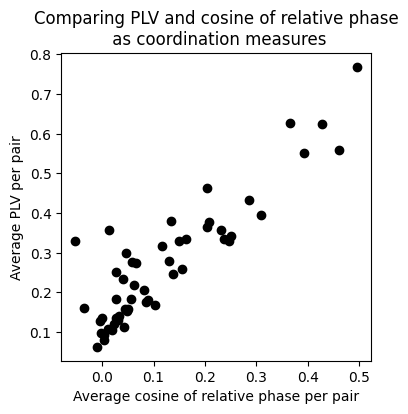

In [8]:
### PLV vs Cos of phase difference

mean_plv_array = plv_array.mean(-1)

print(scipy.stats.pearsonr(mean_cosine_array[:,1],mean_plv_array[:,1]))
plt.figure(figsize=(4,4),dpi=100)
plt.plot(mean_cosine_array[:,1],mean_plv_array[:,1],'o',color='k')
plt.xlabel('Average cosine of relative phase per pair')
plt.ylabel('Average PLV per pair')
plt.title('Comparing PLV and cosine of relative phase\n as coordination measures')
plt.show()

# 2. Running the pipeline

In [25]:
### Setting common parameters

# ~ 1. load behavioral data

with open(f'{base_folder}/intermediate_files/phase_list.pickle', 'rb') as handle:
    phase_list = pickle.load(handle)

# ~ 1.1. remove a bad behavioral trial in the middle of session with pair 45

phase_list[43][0][0] = np.concatenate([phase_list[43][0][0][0:10],phase_list[43][0][0][11:]])
phase_list[43][0][1] = np.concatenate([phase_list[43][0][1][0:10],phase_list[43][0][1][11:]])
phase_list[43][0][2] = np.concatenate([phase_list[43][0][2][0:10],phase_list[43][0][2][11:]])

phase_list[43][1][0] = np.concatenate([phase_list[43][1][0][0:10],phase_list[43][1][0][11:]])
phase_list[43][1][1] = np.concatenate([phase_list[43][1][1][0:10],phase_list[43][1][1][11:]])
phase_list[43][1][2] = np.concatenate([phase_list[43][1][2][0:10],phase_list[43][1][2][11:]])

phase_ar = np.asarray(phase_list)

# ~ 1.2. remove the first two seconds of each trial
phase_ar_cut = phase_ar[..., 480:]
phase_ar_cut_cos = np.cos(phase_ar_cut)
phase_ar_cut_sin = np.sin(phase_ar_cut)
print(phase_ar_cut.shape)
print(phase_ar_cut_cos.shape)
print(phase_ar_cut_sin.shape)


# ~ 1. Loading the dictionary with bad short epochs
with open(f'{base_folder}/data/dict_with_short_bad_epochs.pickle', 'rb') as f:
    bad_short_epochs = pickle.load(f)

all_pairs = [2010,2020,2030,2040,2050,2060,2070,2080,2090,2100,2110,2120,2130,2140,2150,2160,2170,2180,2190,2200,
             2210,2220,2230,2240,2250,2260,2270,2280,2290,2300,2310,2320,2330,2340,2350,2360,2370,2380,2390,
             2410,2420,2430,2440,2450,2460,2470,2480,2490,2500,2510,2520,2530]

number_of_pairs = len(all_pairs)

conditions = ['closed1','open','closed2']

fs = 240
tmin, tmax = -0.250, 0.300  # range of time lags
regularization = np.logspace(-1, 6, 10)

def run_trf_forward_rsq(stimulus,response):
    trf = TRF(direction=1,preload=False)
    result = nested_crossval(
        model=trf, stimulus=stimulus, response=response, fs=fs, tmin=tmin, tmax=tmax, regularization=regularization,k=5,seed=123,n_jobs=-1
        )
    return(result) # via Fisher's z transformation

(52, 2, 3, 20, 4320)
(52, 2, 3, 20, 4320)
(52, 2, 3, 20, 4320)


In [ ]:
### Using all electrodes and R-sq

def segment_to_epoch(segment_num, n_epochs, n_segments_per_epoch):
    block_index = (segment_num - 1) // n_epochs
    original_epoch_index = (segment_num - 1) % n_epochs
    original_epoch_num = original_epoch_index + 1
    return original_epoch_num

variables = ['Full','SelfOther','SelfCoordination','OtherCoordination']

trf_long_all_rsq_sin_cos = {}
for condition in conditions:
    for v in variables:    
        trf_long_all_rsq_sin_cos[f"{condition}_{v}"] = []

for p in range(number_of_pairs):
    pair_n = all_pairs[p]
    print(pair_n)
    folder =f'{base_folder}/data/pair{str(pair_n)}'

    # 1. Loading the files, removing first 2 seconds for each condition and first 2 practice trials (6 epochs)
    if pair_n == 2030:
        practice_trial_cut = 12
    else:
        practice_trial_cut = 6
    epochs_full_a = mne.read_epochs(pathlib.Path(folder+f'/a_ave_epo.fif'),verbose=False).crop(tmin=2)[practice_trial_cut:]
    epochs_full_b = mne.read_epochs(pathlib.Path(folder+f'/b_ave_epo.fif'),verbose=False).crop(tmin=2)[practice_trial_cut:]

    for c in range(len(conditions)):
        condition = conditions[c]
        bad_epochs = bad_short_epochs[str(pair_n) + '_' + condition] # short ones
        bad_e = list(np.unique([segment_to_epoch(i,20,3) for i in bad_epochs])) # convert to long
        good_e = [i for i in range(20) if i not in bad_e]

        s1 = epochs_full_a.copy()
        s1 = s1[condition][good_e].resample(sfreq = 240) # downsample from 256 to 240 to match movement sfreq
        s1_zscored = zscore(s1.get_data(),axis=-1)
        s1_data = list(s1_zscored.transpose(0, 2, 1))

        s2 = epochs_full_b.copy()
        s2 = s2[condition][good_e].resample(sfreq = 240) # downsample from 256 to 240 to match movement sfreq
        s2_zscored = zscore(s2.get_data(),axis=-1)
        s2_data = list(s2_zscored.transpose(0, 2, 1))

        p1_raw_phase = phase_ar_cut[p][0][c][good_e]
        p1_movement_clean_cos = phase_ar_cut_cos[p][0][c][good_e]
        p1_movement_clean_sin = phase_ar_cut_sin[p][0][c][good_e]

        p2_raw_phase = phase_ar_cut[p][1][c][good_e]
        p2_movement_clean_cos = phase_ar_cut_cos[p][1][c][good_e]
        p2_movement_clean_sin = phase_ar_cut_sin[p][1][c][good_e]

        phase_diff_list = []
        for i in range(len(p1_raw_phase)):
            phase_diff = np.cos(md.new_rel_phase(p1_raw_phase[i],p2_raw_phase[i]))
            phase_diff_list.append(phase_diff)
        phase_diff_ar = np.array(phase_diff_list)

        full_p1 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,p2_movement_clean_cos,p2_movement_clean_sin,phase_diff_ar], axis=1) # self, other, sync
        full_p1 = list(full_p1.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_Full"].append(run_trf_forward_rsq(full_p1,s1_data))

        full_p2 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,p1_movement_clean_cos,p1_movement_clean_sin,phase_diff_ar], axis=1) # self, other, sync
        full_p2 = list(full_p2.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_Full"].append(run_trf_forward_rsq(full_p2,s2_data))

        self_other_p1 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,p2_movement_clean_cos,p2_movement_clean_sin], axis=1)
        self_other_p1 = list(self_other_p1.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_SelfOther"].append(run_trf_forward_rsq(self_other_p1,s1_data))

        self_other_p2 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,p1_movement_clean_cos,p1_movement_clean_sin], axis=1)
        self_other_p2 = list(self_other_p2.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_SelfOther"].append(run_trf_forward_rsq(self_other_p2,s2_data))

        self_coordination_p1 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,phase_diff_ar], axis=1)
        self_coordination_p1 = list(self_coordination_p1.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_SelfCoordination"].append(run_trf_forward_rsq(self_coordination_p1,s1_data))

        self_coordination_p2 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,phase_diff_ar], axis=1)
        self_coordination_p2 = list(self_coordination_p2.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_SelfCoordination"].append(run_trf_forward_rsq(self_coordination_p2,s2_data))

        other_coordination_p1 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,phase_diff_ar], axis=1)
        other_coordination_p1 = list(other_coordination_p1.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_OtherCoordination"].append(run_trf_forward_rsq(other_coordination_p1,s1_data))

        other_coordination_p2 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,phase_diff_ar], axis=1)
        other_coordination_p2 = list(other_coordination_p2.transpose(0, 2, 1))
        trf_long_all_rsq_sin_cos[f"{condition}_OtherCoordination"].append(run_trf_forward_rsq(other_coordination_p2,s2_data))
    
    ### Save the dictionary
    #with open(f'{base_folder}/intermediate_files/trf_long_all_rsq_sin_cos_2.pickle', 'wb') as handle:
    #    pickle.dump(trf_long_all_rsq_sin_cos, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 3. Results

In [4]:
### Defining functions for presenting the results

conditions = ['closed1', 'open', 'closed2']
conditions_renamed = ['Before', 'Vision', 'After']
conditions_renamed_dict = dict(zip(conditions,conditions_renamed))

vars = ['self', 'other', 'coordination']
vars_renamed = ['self', 'partner', 'coordination']
vars_renamed_dict = dict(zip(vars,vars_renamed))

def fisher_mean(list_of_tuples_per_condition_and_variable):
    return [np.tanh(np.mean(np.arctanh(i[2]))) for i in list_of_tuples_per_condition_and_variable] # 0 is r, 1 is lambda, and 2 is R-sq per fold

def trf_dict_per_vairable(trf_results):
    trf_per_variable = {}
    for condition in conditions_renamed:
        for v in ['self','other','coordination','full']:
            trf_per_variable[f"{condition}_{v}"] = []

    for condition in conditions:
        for v in ['self','other','coordination','full']:
            res_full = np.array(fisher_mean(trf_results[f'{condition}_Full']))
            if v == 'self':
                res = res_full - np.array(fisher_mean(trf_results[f'{condition}_OtherCoordination']))
            elif v == 'other':
                res = res_full - np.array(fisher_mean(trf_results[f'{condition}_SelfCoordination']))
            elif v == 'coordination':
                res = res_full - np.array(fisher_mean(trf_results[f'{condition}_SelfOther']))
            elif v == 'full':
                res = res_full
            trf_per_variable[f"{conditions_renamed_dict[condition]}_{v}"] = res
    return(trf_per_variable)


def plot_trf_results(trf_per_variable,area):
    rows = []
    for condition in conditions_renamed:
        for var in vars:
            key = f"{condition}_{var}"
            vals = trf_per_variable[key]  # <- your list/array of values
            for val in vals:
                rows.append({
                    "Condition": condition,
                    "Variable": vars_renamed_dict[var],
                    "ΔR²": val
                })

    df = pd.DataFrame(rows)

    plt.figure(figsize=(8, 4),dpi=500)
    sns.set(style="whitegrid")

    df["Condition"] = pd.Categorical(df["Condition"], conditions_renamed)

    cmap = plt.get_cmap('bone')
    palette = cmap(np.linspace(0.3, 0.75, 3))

    pt.RainCloud(
        x="Variable",
        y="ΔR²",
        hue="Condition",
        data=df,
        palette='Set2',
        width_viol=0.3,
        width_box=0.4,
        orient="v",
        alpha=0.9,
        dodge=True,
        pointplot = False,
        box_medianprops={"zorder": 11},
        box_fliersize=0,
    )
    #plt.ylim(-0.0050,0.0175)
    plt.title(f"EEG TRF model fit ({area})")
    plt.tight_layout()
    plt.show()

def quick_stats(trf_per_variable):
    quick_results = {
    'Condition': [],
    'Variable': [],
    'Median ΔR²':[],
    'p-val (adjusted)':[]
    }

    for condition in conditions_renamed:
        for sub in ["self", "other", "coordination"]:
            key = f"{condition}_{sub}"
            mn = np.median(trf_per_variable[key])
            pval = round(scipy.stats.wilcoxon(trf_per_variable[key])[1],6)
            pval = scipy.stats.false_discovery_control(pval) # FDR correction
            quick_results['Condition'].append(condition)
            quick_results['Variable'].append(sub)
            quick_results['Median ΔR²'].append(mn)
            quick_results['p-val (adjusted)'].append(pval)
    return(pd.DataFrame(quick_results))

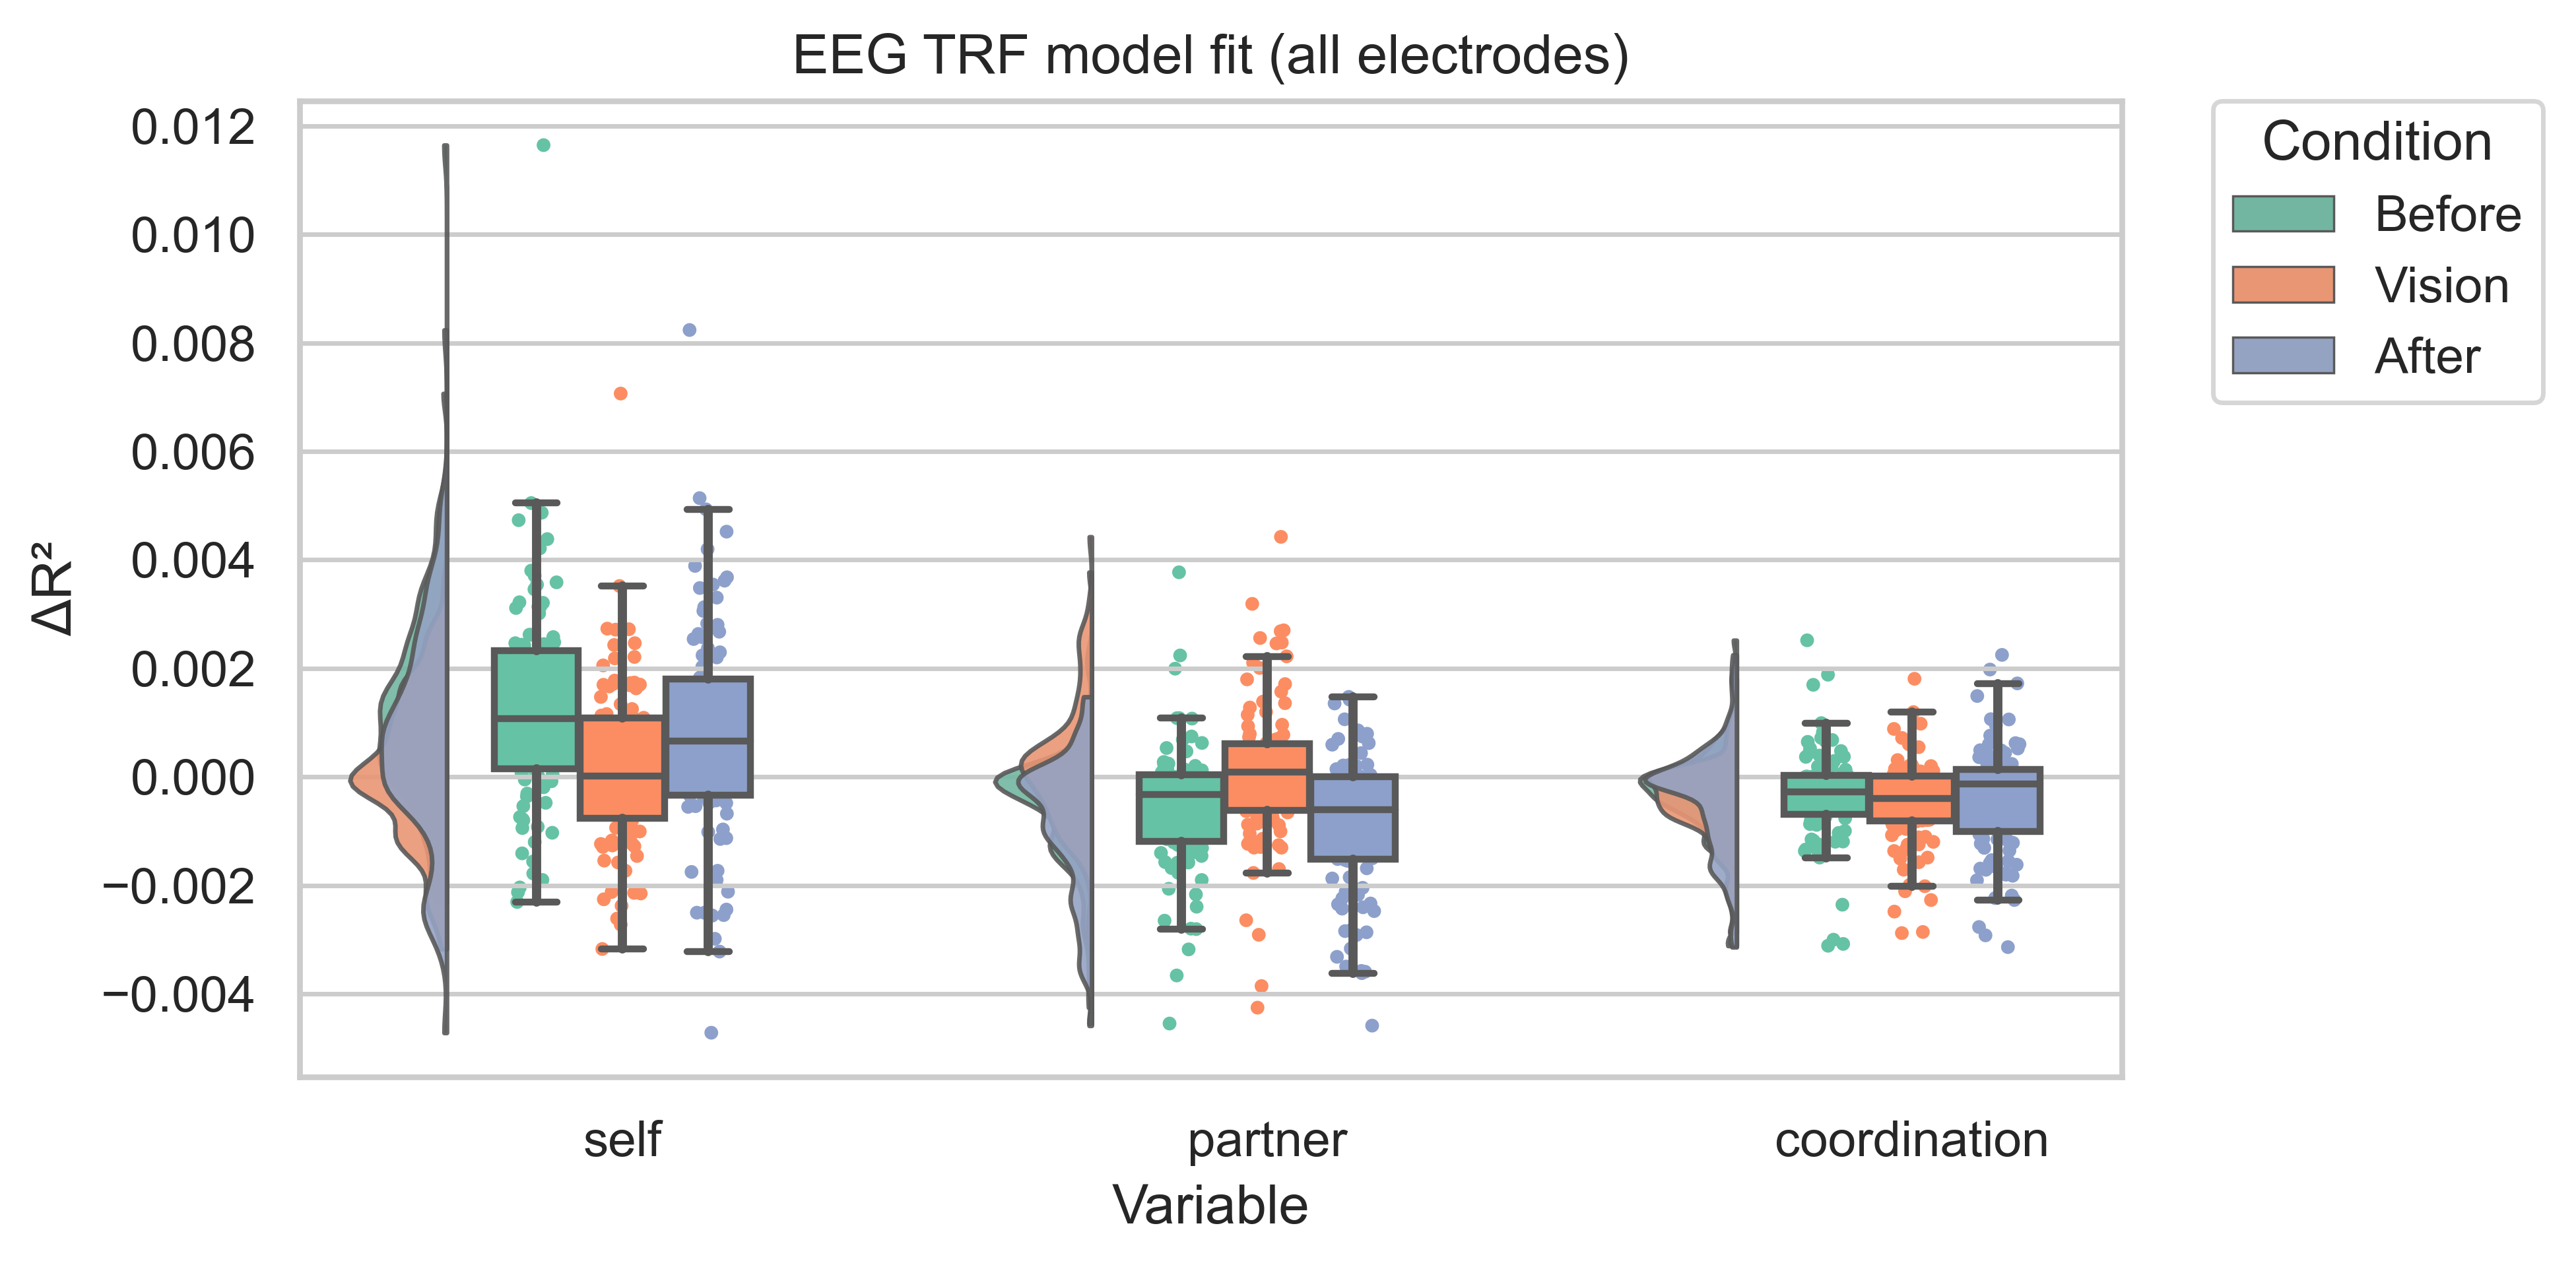

,Condition,Variable,Median ΔR²,p-val (adjusted)
0,Before,self,0.001068,0.000000
1,Before,other,-0.000322,0.000001
2,Before,coordination,-0.000279,0.000021
3,Vision,self,0.000009,0.275750
4,Vision,other,0.000090,0.509709
5,Vision,coordination,-0.000403,0.000000
6,After,self,0.000659,0.000330
7,After,other,-0.000607,0.000000
8,After,coordination,-0.000138,0.000212


In [5]:
with open(f'{base_folder}/intermediate_files/trf_long_all_rsq_sin_cos_2.pickle', 'rb') as handle:
    trf_long_all_rsq = pickle.load(handle)

all_trf = trf_dict_per_vairable(trf_long_all_rsq)
all_trf_trigger_dict = {k: np.delete(v, [2, 3]) for k, v in all_trf.items()}
plot_trf_results(all_trf_trigger_dict,'all electrodes')
quick_stats(all_trf_trigger_dict)

In [6]:
for k in all_trf_trigger_dict:
    print(k, round(np.std(all_trf_trigger_dict[k]),4))

Before_self 0.0019
Before_other 0.0011
Before_coordination 0.0008
Before_full 0.0019
Vision_self 0.0015
Vision_other 0.0013
Vision_coordination 0.0008
Vision_full 0.0018
After_self 0.002
After_other 0.0012
After_coordination 0.001
After_full 0.0023


In [7]:
print('Self')
pv1 = scipy.stats.wilcoxon(all_trf_trigger_dict['Vision_self'],all_trf_trigger_dict['Before_self'])[1]*3
print(f"Vision vs Before: p-val = {pv1}")
pv2 = scipy.stats.wilcoxon(all_trf_trigger_dict['Vision_self'],all_trf_trigger_dict['After_self'])[1]*3
print(f"Vision vs After: p-val = {pv2}")
pv3 = scipy.stats.wilcoxon(all_trf_trigger_dict['Before_self'],all_trf_trigger_dict['After_self'])[1]*3
print(f"Before vs After: p-val = {pv3}")

print('\nOther')
pv4 = scipy.stats.wilcoxon(all_trf_trigger_dict['Vision_other'],all_trf_trigger_dict['Before_other'])[1]*3
print(f"Vision vs Before: p-val = {pv4}")
pv5 = scipy.stats.wilcoxon(all_trf_trigger_dict['Vision_other'],all_trf_trigger_dict['After_other'])[1]*3
print(f"Vision vs After: p-val = {pv5}")
pv6 = scipy.stats.wilcoxon(all_trf_trigger_dict['Before_other'],all_trf_trigger_dict['After_other'])[1]*3
print(f"Before vs After: p-val = {pv6}")

print('\nCoordination')
pv7 = scipy.stats.wilcoxon(all_trf_trigger_dict['Vision_coordination'],all_trf_trigger_dict['Before_coordination'])[1]*3
print(f"Vision vs Before: p-val = {pv7}")
pv8 = scipy.stats.wilcoxon(all_trf_trigger_dict['Vision_coordination'],all_trf_trigger_dict['After_coordination'])[1]*3
print(f"Vision vs After: p-val = {pv8}")
pv9 = scipy.stats.wilcoxon(all_trf_trigger_dict['Before_coordination'],all_trf_trigger_dict['After_coordination'])[1]*3
print(f"Before vs After: p-val = {pv9}")

Self
Vision vs Before: p-val = 7.609734749363653e-06
Vision vs After: p-val = 0.10770290286153811
Before vs After: p-val = 0.30049479666882883

Other
Vision vs Before: p-val = 0.0005811328670690797
Vision vs After: p-val = 6.223265791035695e-07
Before vs After: p-val = 0.4380234299244812

Coordination
Vision vs Before: p-val = 0.20130487690033064
Vision vs After: p-val = 0.9474036192637033
Before vs After: p-val = 1.5810131509094218


In [ ]:
### Visualization (topographies)

def get_pred_rsq_electrode(stim,resp,lamb):
    fs = 240
    tmin, tmax = -0.250, 0.300  # range of time lags

    fwd_trf = TRF(direction=1)
    fwd_trf.train(stim, resp, fs, tmin, tmax, lamb) # train the model using lambda from cross-validation
    prediction = fwd_trf.predict(stim) # predict EEG given the stimuli
    prediction = np.array(prediction).transpose([0,2,1])
    resp = np.array(resp).transpose([0,2,1])
    # ~ calculate R-squared
    residuals = resp - prediction
    ss_res = np.sum(residuals**2, axis=2)
    ss_tot = np.sum((resp - np.mean(resp, axis=2, keepdims=True))**2, axis=2)
    r_squared_per_trial = 1 - (ss_res / ss_tot)
    r_squared_avg = np.mean(r_squared_per_trial, axis=0)
    return(r_squared_avg)

def segment_to_epoch(segment_num, n_epochs, n_segments_per_epoch):
    block_index = (segment_num - 1) // n_epochs
    original_epoch_index = (segment_num - 1) % n_epochs
    original_epoch_num = original_epoch_index + 1
    return original_epoch_num


condition = 'open'
variables = ['full','self','other','coordination']

trf_visualization_final = {}
for v in variables:    
    trf_visualization_final[f"{condition}_{v}"] = []


for p in range(number_of_pairs):

    trf_visualization_intermediate_p1 = {}
    for v in variables:    
        trf_visualization_intermediate_p1[f"{condition}_{v}"] = []

    trf_visualization_intermediate_p2 = {}
    for v in variables:    
        trf_visualization_intermediate_p2[f"{condition}_{v}"] = []


    pair_n = all_pairs[p]
    print(pair_n)
    folder = f"/Users/aldab/Documents/circling_experiment_data/pair{str(pair_n)}"

    # 1. Loading the files, removing first 2 seconds for each condition and first 2 practice trials (6 epochs)
    if pair_n == 2030:
        practice_trial_cut = 12
    else:
        practice_trial_cut = 6
    epochs_full_a = mne.read_epochs(pathlib.Path(folder+f'/a_ave_epo.fif'),verbose=False).crop(tmin=2)[practice_trial_cut:]
    epochs_full_b = mne.read_epochs(pathlib.Path(folder+f'/b_ave_epo.fif'),verbose=False).crop(tmin=2)[practice_trial_cut:]

    bad_epochs = bad_short_epochs[str(pair_n) + '_' + condition] # short ones
    bad_e = list(np.unique([segment_to_epoch(i,20,3) for i in bad_epochs])) # convert to long
    good_e = [i for i in range(20) if i not in bad_e]

    s1 = epochs_full_a.copy()
    s1 = s1[condition][good_e].resample(sfreq = 240) # downsample from 256 to 240 to match movement sfreq
    s1_zscored = zscore(s1.get_data(),axis=-1)
    s1_data = list(s1_zscored.transpose(0, 2, 1))

    s2 = epochs_full_b.copy()
    s2 = s2[condition][good_e].resample(sfreq = 240) # downsample from 256 to 240 to match movement sfreq
    s2_zscored = zscore(s2.get_data(),axis=-1)
    s2_data = list(s2_zscored.transpose(0, 2, 1))

    p1_raw_phase = phase_ar_cut[p][0][1][good_e]
    p1_movement_clean_cos = phase_ar_cut_cos[p][0][1][good_e]
    p1_movement_clean_sin = phase_ar_cut_sin[p][0][1][good_e]

    p2_raw_phase = phase_ar_cut[p][1][1][good_e]
    p2_movement_clean_cos = phase_ar_cut_cos[p][1][1][good_e]
    p2_movement_clean_sin = phase_ar_cut_sin[p][1][1][good_e]

    phase_diff_list = []
    for i in range(len(p1_raw_phase)):
        phase_diff = np.cos(md.new_rel_phase(p1_raw_phase[i],p2_raw_phase[i]))
        phase_diff_list.append(phase_diff)
    phase_diff_ar = np.array(phase_diff_list)

    full_p1 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,p2_movement_clean_cos,p2_movement_clean_sin,phase_diff_ar], axis=1) # self, other, sync
    full_p1 = list(full_p1.transpose(0, 2, 1))

    full_p2 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,p1_movement_clean_cos,p1_movement_clean_sin,phase_diff_ar], axis=1) # self, other, sync
    full_p2 = list(full_p2.transpose(0, 2, 1))

    self_other_p1 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,p2_movement_clean_cos,p2_movement_clean_sin], axis=1)
    self_other_p1 = list(self_other_p1.transpose(0, 2, 1))

    self_other_p2 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,p1_movement_clean_cos,p1_movement_clean_sin], axis=1)
    self_other_p2 = list(self_other_p2.transpose(0, 2, 1))

    self_coordination_p1 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,phase_diff_ar], axis=1)
    self_coordination_p1 = list(self_coordination_p1.transpose(0, 2, 1))

    self_coordination_p2 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,phase_diff_ar], axis=1)
    self_coordination_p2 = list(self_coordination_p2.transpose(0, 2, 1))

    other_coordination_p1 = np.stack([p2_movement_clean_cos,p2_movement_clean_sin,phase_diff_ar], axis=1)
    other_coordination_p1 = list(other_coordination_p1.transpose(0, 2, 1))

    other_coordination_p2 = np.stack([p1_movement_clean_cos,p1_movement_clean_sin,phase_diff_ar], axis=1)
    other_coordination_p2 = list(other_coordination_p2.transpose(0, 2, 1))

    full_lamb_p1 = np.median(trf_long_all_rsq['open_Full'][p*2][1])
    full_trf_p1 = get_pred_rsq_electrode(full_p1,s1_data,full_lamb_p1)
    trf_visualization_intermediate_p1[f"{condition}_full"].append(full_trf_p1)

    full_lamb_p2 = np.median(trf_long_all_rsq['open_Full'][p*2+1][1])
    full_trf_p2 = get_pred_rsq_electrode(full_p2,s2_data,full_lamb_p2)
    trf_visualization_intermediate_p2[f"{condition}_full"].append(full_trf_p2)

    self_other_lamb_p1 = np.median(trf_long_all_rsq['open_SelfOther'][p*2][1])
    self_other_trf_p1 = get_pred_rsq_electrode(self_other_p1,s1_data,self_other_lamb_p1)
    trf_visualization_intermediate_p1[f"{condition}_coordination"].append(full_trf_p1-self_other_trf_p1)

    self_other_lamb_p2 = np.median(trf_long_all_rsq['open_SelfOther'][p*2+1][1])
    self_other_trf_p2 = get_pred_rsq_electrode(self_other_p2,s2_data,self_other_lamb_p2)
    trf_visualization_intermediate_p2[f"{condition}_coordination"].append(full_trf_p2-self_other_trf_p2)

    self_coordination_lamb_p1 = np.median(trf_long_all_rsq['open_SelfCoordination'][p*2][1])
    self_coordination_trf_p1 = get_pred_rsq_electrode(self_coordination_p1,s1_data,self_coordination_lamb_p1)
    trf_visualization_intermediate_p1[f"{condition}_other"].append(full_trf_p1-self_coordination_trf_p1)

    self_coordination_lamb_p2 = np.median(trf_long_all_rsq['open_SelfCoordination'][p*2+1][1])
    self_coordination_trf_p2 = get_pred_rsq_electrode(self_coordination_p2,s2_data,self_coordination_lamb_p2)
    trf_visualization_intermediate_p2[f"{condition}_other"].append(full_trf_p2-self_coordination_trf_p2)


    other_coordination_lamb_p1 = np.median(trf_long_all_rsq['open_OtherCoordination'][p*2][1])
    other_coordination_trf_p1 = get_pred_rsq_electrode(other_coordination_p1,s1_data,other_coordination_lamb_p1)
    trf_visualization_intermediate_p1[f"{condition}_self"].append(full_trf_p1-other_coordination_trf_p1)

    other_coordination_lamb_p2 = np.median(trf_long_all_rsq['open_OtherCoordination'][p*2+1][1])
    other_coordination_trf_p2 = get_pred_rsq_electrode(other_coordination_p2,s2_data,other_coordination_lamb_p2)
    trf_visualization_intermediate_p2[f"{condition}_self"].append(full_trf_p2-other_coordination_trf_p2)

    for v in variables:    
        trf_visualization_final[f"{condition}_{v}"].append(trf_visualization_intermediate_p1[f"{condition}_{v}"])
        trf_visualization_final[f"{condition}_{v}"].append(trf_visualization_intermediate_p2[f"{condition}_{v}"])
    
    ### Save the dictionary
    #with open(f'{base_folder}/intermediate_files/trf_visualization_sin_cos_2.pickle', 'wb') as handle:
    #    pickle.dump(trf_visualization_final, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [7]:
with open(f'{base_folder}/intermediate_files/trf_visualization_sin_cos_2.pickle', 'rb') as handle:
    trf_visualization_final = pickle.load(handle)

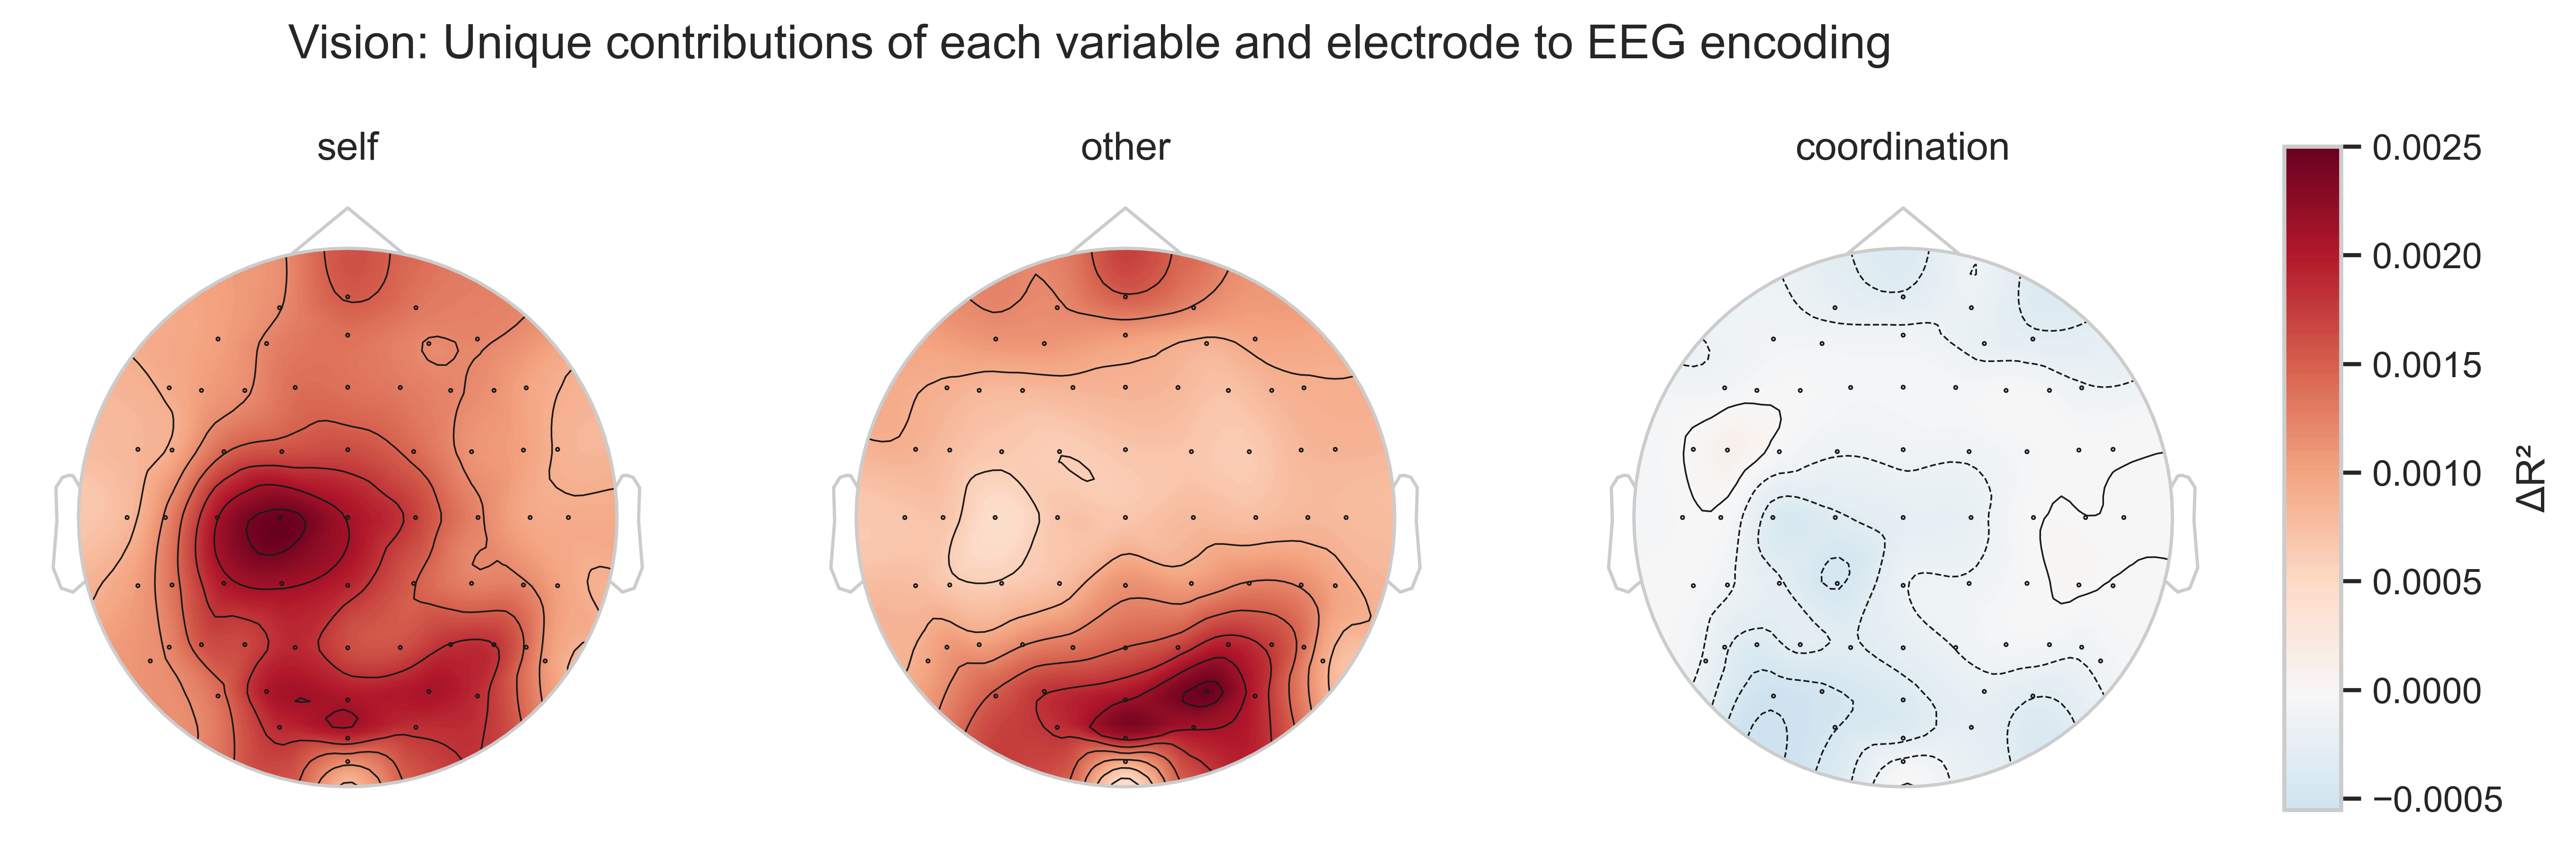

In [8]:
import mne
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.colors as mcolors
import matplotlib.cm as cmm

pair_n = '2010'
folder = f'{base_folder}/data/pair{str(pair_n)}'
epochs_full_a = mne.read_epochs(pathlib.Path(folder+f'/a_ave_epo.fif'), verbose=False)
info = epochs_full_a.info

vis_trig = {k: v[:1] + v[3:] for k, v in trf_visualization_final.items()} ### removing the pair with reconstructed triggers

cmap = LinearSegmentedColormap.from_list("white_red", ["white", "red"])

variables = ['self', 'other','coordination']


def shift_and_extend_cmap(cmap, shift=0.0, start=0.0, stop=1.0):
    """
    Shift and extend a colormap.
    :param cmap: original colormap (e.g., cm.bone)
    :param shift: fraction to shift the colormap (0-1)
    :param start: new start of the colormap (0-1)
    :param stop: new end of the colormap (0-1)
    :return: new LinearSegmentedColormap
    """
    # Original colors
    colors = cmap(np.linspace(0, 1, 256))
    
    # Shift
    colors = np.roll(colors, int(shift * 256), axis=0)
    
    # Stretch/compress by resampling
    indices = np.linspace(start, stop, 256)
    new_colors = colors[(indices * 255).astype(int)]
    
    return mcolors.LinearSegmentedColormap.from_list(f'shifted_extended_{cmap.name}', new_colors)

# Compute min and max across all variables
all_r2 = []
for var in variables:
    r2 = np.mean(np.array(vis_trig[f'open_{var}']).reshape(102,64),axis=0)
    all_r2.append(r2)
all_r2 = np.array(all_r2)
#vmin, vmax = 0, 0.0008
vmin, vmax = all_r2.min(), 0.0025

# Create a single-row figure
fig, ax = plt.subplots(1, 3, figsize=(12, 4), dpi=500)
fig.suptitle('Vision: Unique contributions of each variable and electrode to EEG encoding')

for i, var in enumerate(variables):
    r_squared_per_electrode = all_r2[i]

    # Plot topomap
    im, cm = mne.viz.plot_topomap(
        r_squared_per_electrode, info,
        axes=ax[i], show=False,
        cmap=shift_and_extend_cmap(cmm.RdBu_r,0,0.397,1),
        sensors=True, contours=6, outlines='head'
    )

    # Set consistent color limits
    im.set_clim(vmin, vmax)
    ax[i].set_title(var)

# Add a single colorbar
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
fig.colorbar(im, cax=cax, label='ΔR²')

#plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

# 4. Connecting mTRF results to network parameters

In [6]:
pairwise_df = pd.read_csv(f'{base_folder}/intermediate_files/full_df_pairwise.csv').iloc[::60].reset_index().drop(columns=['index','Unnamed: 0','trial_plv','cond'])

pairlog = pd.read_csv(f"{base_folder}/data/PairLog_CirclingExperiment.csv",delimiter=';').loc[:,['p1_gender','p2_gender']].reset_index().drop(columns=['index'])
pairlog = pairlog.drop([39]).reset_index().drop(columns=['index'])
individual_gender = []
for i in range(len(pairlog)):
    g = str(pairlog.loc[i,'p1_gender'])+str(pairlog.loc[i,'p2_gender'])
    individual_gender.append(g)

fully_individual_gender = []
for i in range(len(pairlog)):
    fully_individual_gender.append(str(pairlog.loc[i,'p1_gender']))
    fully_individual_gender.append(str(pairlog.loc[i,'p2_gender']))

network_pca_individual = pd.read_csv(f'{base_folder}/intermediate_files/network_pca_individual.csv').drop("Unnamed: 0",axis=1)
network_pca_individual['Vision_self'] = all_trf['Vision_self']
network_pca_individual['Vision_other'] = all_trf['Vision_other']
network_pca_individual['Vision_full'] = all_trf['Vision_full']
network_pca_individual['Vision_coordination'] = all_trf['Vision_coordination']
network_pca_individual['pair'] = md.flatten([[i,i] for i in all_pairs])
network_pca_individual['fully_individual_gender'] = fully_individual_gender

personality_individual = pd.read_csv(f'{base_folder}/intermediate_files/personality_results_individual.csv').drop("Unnamed: 0",axis=1)

network_pca_individual['Conscientiousness'] = personality_individual['Conscientiousness']
network_pca_individual['Agreeableness'] = personality_individual['Agreeableness']
network_pca_individual['Neuroticism'] = personality_individual['Neuroticism']
network_pca_individual['Extraversion'] = personality_individual['Extraversion']
network_pca_individual['Openness'] = personality_individual['Openness']

#network_pca_individual.to_csv(f"{base_folder}/intermediate_files/trf_df_individual.csv")

def pair_diff_array(arr):
    return [arr[i] - arr[i+1] for i in range(0,len(arr)-1,2)]

trf_df = pairwise_df.copy()
trf_df['Other_diff'] = pair_diff_array(all_trf['Vision_other'])
trf_df['Self_diff'] = pair_diff_array(all_trf['Vision_self'])
trf_df['individual_gender'] = individual_gender

trf_df['Conscientiousness'] = pair_diff_array(personality_individual['Conscientiousness'])
trf_df['Agreeableness'] = pair_diff_array(personality_individual['Agreeableness'])
trf_df['Neuroticism'] = pair_diff_array(personality_individual['Neuroticism'])
trf_df['Extraversion'] = pair_diff_array(personality_individual['Extraversion'])
trf_df['Openness'] = pair_diff_array(personality_individual['Openness'])

#trf_df.to_csv(f"{base_folder}/intermediate_files/trf_df_pairwise.csv")

In [7]:
### Removing a pair with reconstructed triggers
trigger_test = network_pca_individual[(network_pca_individual['subject']!=2021)&((network_pca_individual['subject']!=2022))]

In [8]:
### Testing if gender is needed in the model

model1 = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(PC1) + scale(PC2) + scale(PC3)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)

model2 = smf.mixedlm(
    formula="scale(Vision_other) ~ fully_individual_gender + scale(PC1) + scale(PC2) + scale(PC3)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)


In [9]:
from scipy.stats import chi2

lr_stat = 2 * (model2.llf - model1.llf)
df_diff = len(model2.params) - len(model1.params)
p_value = chi2.sf(lr_stat, df_diff)

print(f"LR stat: {lr_stat}")
print(f"df diff: {df_diff}")
print(f"p-value: {p_value}")

LR stat: 2.743389259959713
df diff: 1
p-value: 0.09765744065969384


In [18]:
### Proceeding without gender

model_full = smf.mixedlm(
    formula="scale(Vision_other) ~ fully_individual_gender + scale(PC1) + scale(PC2) + scale(PC3)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=True)
print(model_full.summary())


# ~ Checking is LRT p-value is consistent

model_full = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(PC1) + scale(PC2) + scale(PC3)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)

model_null = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(PC2) + scale(PC3)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)

lr_stat = 2 * (model_full.llf - model_null.llf)
df_diff = len(model_full.params) - len(model_null.params)
p_value = chi2.sf(lr_stat, df_diff)

print(f"LR stat: {lr_stat}")
print(f"df diff: {df_diff}")
print(f"p-value: {p_value}")

                 Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   scale(Vision_other)
No. Observations:   102       Method:               REML               
No. Groups:         51        Scale:                0.8272             
Min. group size:    2         Log-Likelihood:       -147.0244          
Max. group size:    2         Converged:            Yes                
Mean group size:    2.0                                                
-----------------------------------------------------------------------
                             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------------
Intercept                     0.190    0.157  1.205 0.228 -0.119  0.499
fully_individual_gender[T.m] -0.372    0.228 -1.631 0.103 -0.820  0.075
scale(PC1)                   -0.169    0.098 -1.714 0.087 -0.361  0.024
scale(PC2)                    0.026    0.100  0.256 0.798 -0.171  0.222
scale(PC3

/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/iolib/summary2.py:579: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dat = dat.applymap(lambda x: _formatter(x, float_format))


In [13]:
### Checking if the effect holds if a pair with reconstructed triggers is included (it makes the effect stronger)

model_full = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(PC1) + scale(PC2) + scale(PC3)",
    data=network_pca_individual,
    groups=network_pca_individual["pair"]
).fit(reml=True)

print(model_full.summary())

              Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: scale(Vision_other)
No. Observations: 104     Method:             REML               
No. Groups:       52      Scale:              0.8734             
Min. group size:  2       Log-Likelihood:     -150.3733          
Max. group size:  2       Converged:          Yes                
Mean group size:  2.0                                            
-------------------------------------------------------------------
               Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
-------------------------------------------------------------------
Intercept      -0.000      0.103   -0.000   1.000   -0.203    0.203
scale(PC1)     -0.218      0.097   -2.244   0.025   -0.408   -0.028
scale(PC2)      0.039      0.098    0.400   0.689   -0.153    0.232
scale(PC3)      0.016      0.097    0.169   0.866   -0.174    0.207
Group Var       0.119      0.167                                   



/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/iolib/summary2.py:579: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dat = dat.applymap(lambda x: _formatter(x, float_format))


/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


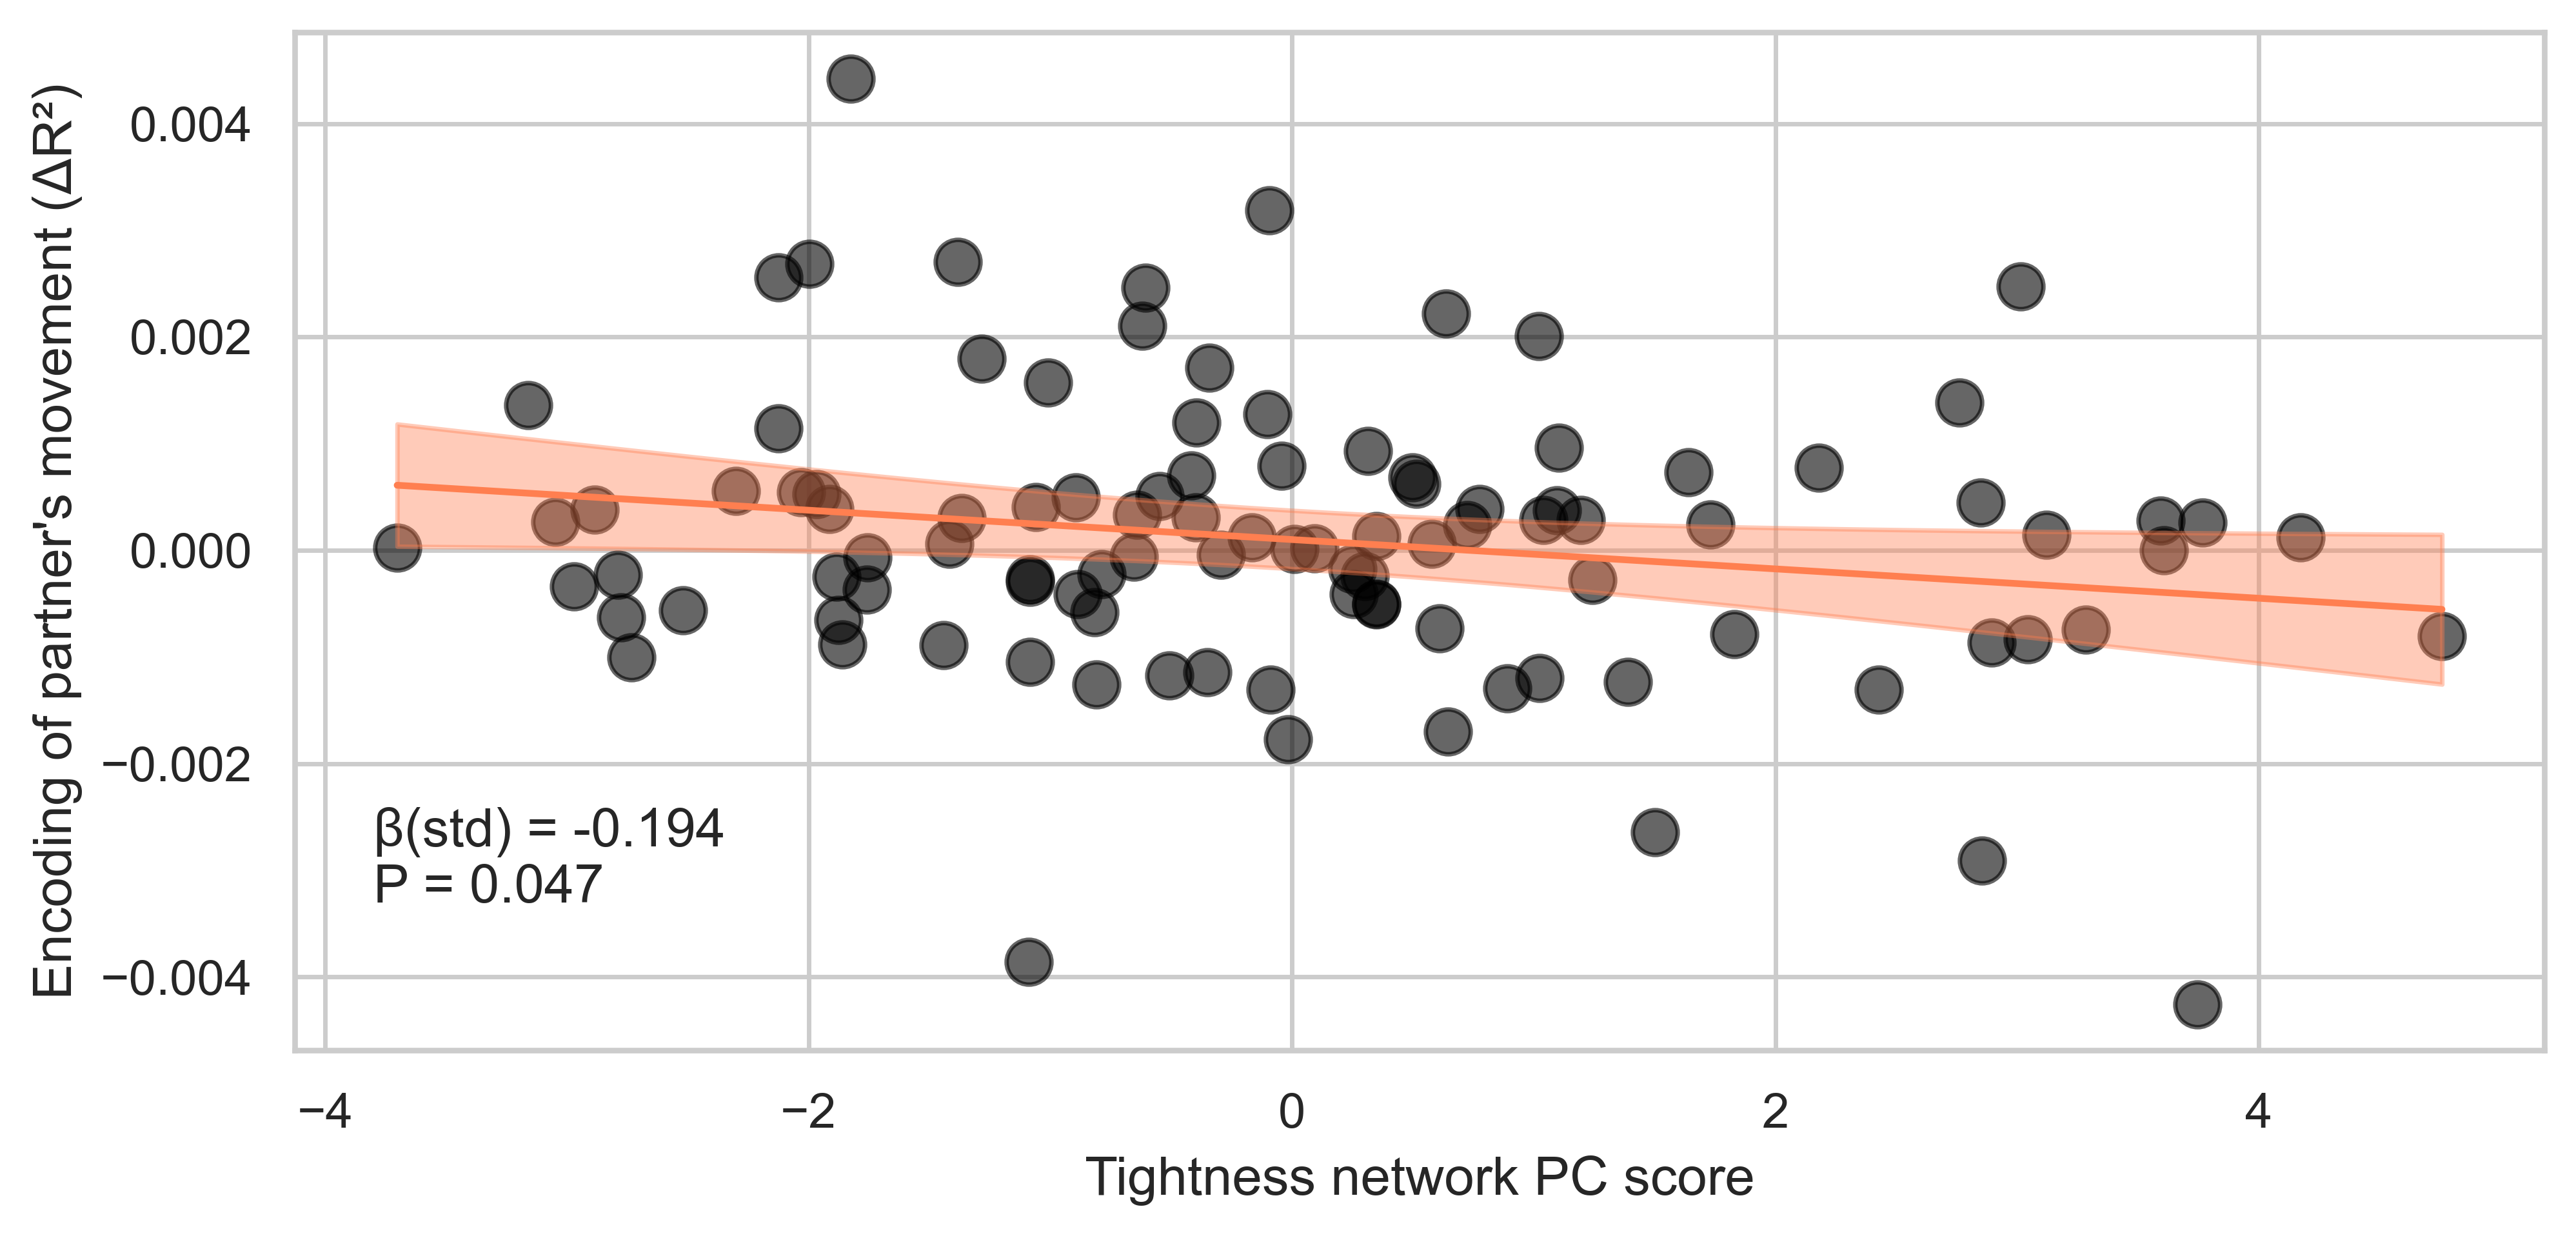

In [22]:
### Visualizing the effect
import patsy

# Fit model
model_full = smf.mixedlm(
    formula="Vision_other ~ PC1 + PC2 + PC3",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=True)

# Grid (PC2, PC3 at mean)
pc1_vals = np.linspace(trigger_test["PC1"].min(),
                       trigger_test["PC1"].max(), 100)

pred_df = pd.DataFrame({
    "PC1": pc1_vals,
    "PC2": trigger_test["PC2"].mean(),
    "PC3": trigger_test["PC3"].mean()
})

# Use the original design_inf
design_info = model_full.model.data.design_info
exog = patsy.build_design_matrices([design_info], pred_df)[0]

# Fixed effects
fe_params = model_full.fe_params.values
cov_fe = model_full.cov_params().loc[
    model_full.fe_params.index,
    model_full.fe_params.index
].values

# Predictions + CI
y_hat = np.asarray(exog @ fe_params).flatten()
se = np.sqrt(np.sum(exog @ cov_fe * exog, axis=1))
ci_lower = y_hat - 1.96 * se
ci_upper = y_hat + 1.96 * se

# Plot
plt.figure(figsize=(9,4.1), dpi=500)
plt.scatter(trigger_test["PC1"], trigger_test["Vision_other"], color='black',alpha=0.6,s=100)
plt.plot(pc1_vals, y_hat,color='coral')
plt.fill_between(pc1_vals, ci_lower, ci_upper, alpha=0.4,color='coral')

text_block = f'β(std) = -0.194\nP = 0.047'
plt.text(-3.8, -0.0034, text_block,
            horizontalalignment='left', verticalalignment='bottom',
            bbox=dict(facecolor='white', alpha=0.8),
            fontsize=12)

plt.xlabel("Tightness network PC score")
plt.ylabel("Encoding of partner's movement (ΔR²)")
#plt.title("Effect of individual network PC1 on partner encoding, controlling for PC2 and PC3")
plt.grid(visible=True)
plt.show()

In [16]:
### Examining the effect on self-encoding

model_full = smf.mixedlm(
    formula="scale(Vision_self) ~ scale(PC1) + scale(PC2) + scale(PC3)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=True)

print(model_full.summary())

             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: scale(Vision_self)
No. Observations: 102     Method:             REML              
No. Groups:       51      Scale:              1.0241            
Min. group size:  2       Log-Likelihood:     -149.4705         
Max. group size:  2       Converged:          Yes               
Mean group size:  2.0                                           
------------------------------------------------------------------
              Coef.    Std.Err.     z      P>|z|   [0.025   0.975]
------------------------------------------------------------------
Intercept     -0.000      0.100   -0.000   1.000   -0.196    0.196
scale(PC1)    -0.124      0.100   -1.236   0.217   -0.321    0.073
scale(PC2)     0.021      0.101    0.210   0.833   -0.176    0.218
scale(PC3)     0.016      0.100    0.159   0.873   -0.181    0.213
Group Var      0.000      0.160                                   



/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/iolib/summary2.py:579: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dat = dat.applymap(lambda x: _formatter(x, float_format))


In [13]:
### Examining the effects of personality factors on the Other encoding

model_full = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(Extraversion) + scale(Neuroticism) + scale(Agreeableness) + scale(Conscientiousness) + scale(Openness)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=True)

print(model_full.summary())

# ~ checking if LRT p-value is consistent

model_full = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(Extraversion) + scale(Neuroticism) + scale(Agreeableness) + scale(Conscientiousness) + scale(Openness)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)

print(model_full.summary())

model_null = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(Neuroticism) + scale(Agreeableness) + scale(Conscientiousness) + scale(Openness)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)

lr_stat = 2 * (model_full.llf - model_null.llf)
df_diff = len(model_full.params) - len(model_null.params)
p_value = chi2.sf(lr_stat, df_diff)

print(f"LR stat: {lr_stat}")
print(f"df diff: {df_diff}")
print(f"p-value: {p_value}")

               Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: scale(Vision_other)
No. Observations:   102     Method:             REML               
No. Groups:         51      Scale:              0.8617             
Min. group size:    2       Log-Likelihood:     -148.2727          
Max. group size:    2       Converged:          Yes                
Mean group size:    2.0                                            
-------------------------------------------------------------------
                         Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------------
Intercept                -0.000    0.103 -0.000 1.000 -0.203  0.203
scale(Extraversion)       0.254    0.112  2.273 0.023  0.035  0.472
scale(Neuroticism)        0.055    0.114  0.480 0.631 -0.169  0.279
scale(Agreeableness)      0.064    0.112  0.572 0.568 -0.155  0.283
scale(Conscientiousness)  0.182    0.105  1.727 0.084 -0.025  0

/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/iolib/summary2.py:579: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dat = dat.applymap(lambda x: _formatter(x, float_format))
/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/iolib/summary2.py:579: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dat = dat.applymap(lambda x: _formatter(x, float_format))


In [19]:
### Examining the need for gender in the personality model

model_full = smf.mixedlm(
    formula="scale(Vision_other) ~ fully_individual_gender + scale(Extraversion) + scale(Neuroticism) + scale(Agreeableness) + scale(Conscientiousness) + scale(Openness)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)

model_null = smf.mixedlm(
    formula="scale(Vision_other) ~ scale(Extraversion) + scale(Neuroticism) + scale(Agreeableness) + scale(Conscientiousness) + scale(Openness)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=False)

lr_stat = 2 * (model_full.llf - model_null.llf)
df_diff = len(model_full.params) - len(model_null.params)
p_value = chi2.sf(lr_stat, df_diff)

print(f"LR stat: {lr_stat}")
print(f"df diff: {df_diff}")
print(f"p-value: {p_value}")

LR stat: 2.5520171749849396
df diff: 1
p-value: 0.11015353608123406


/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


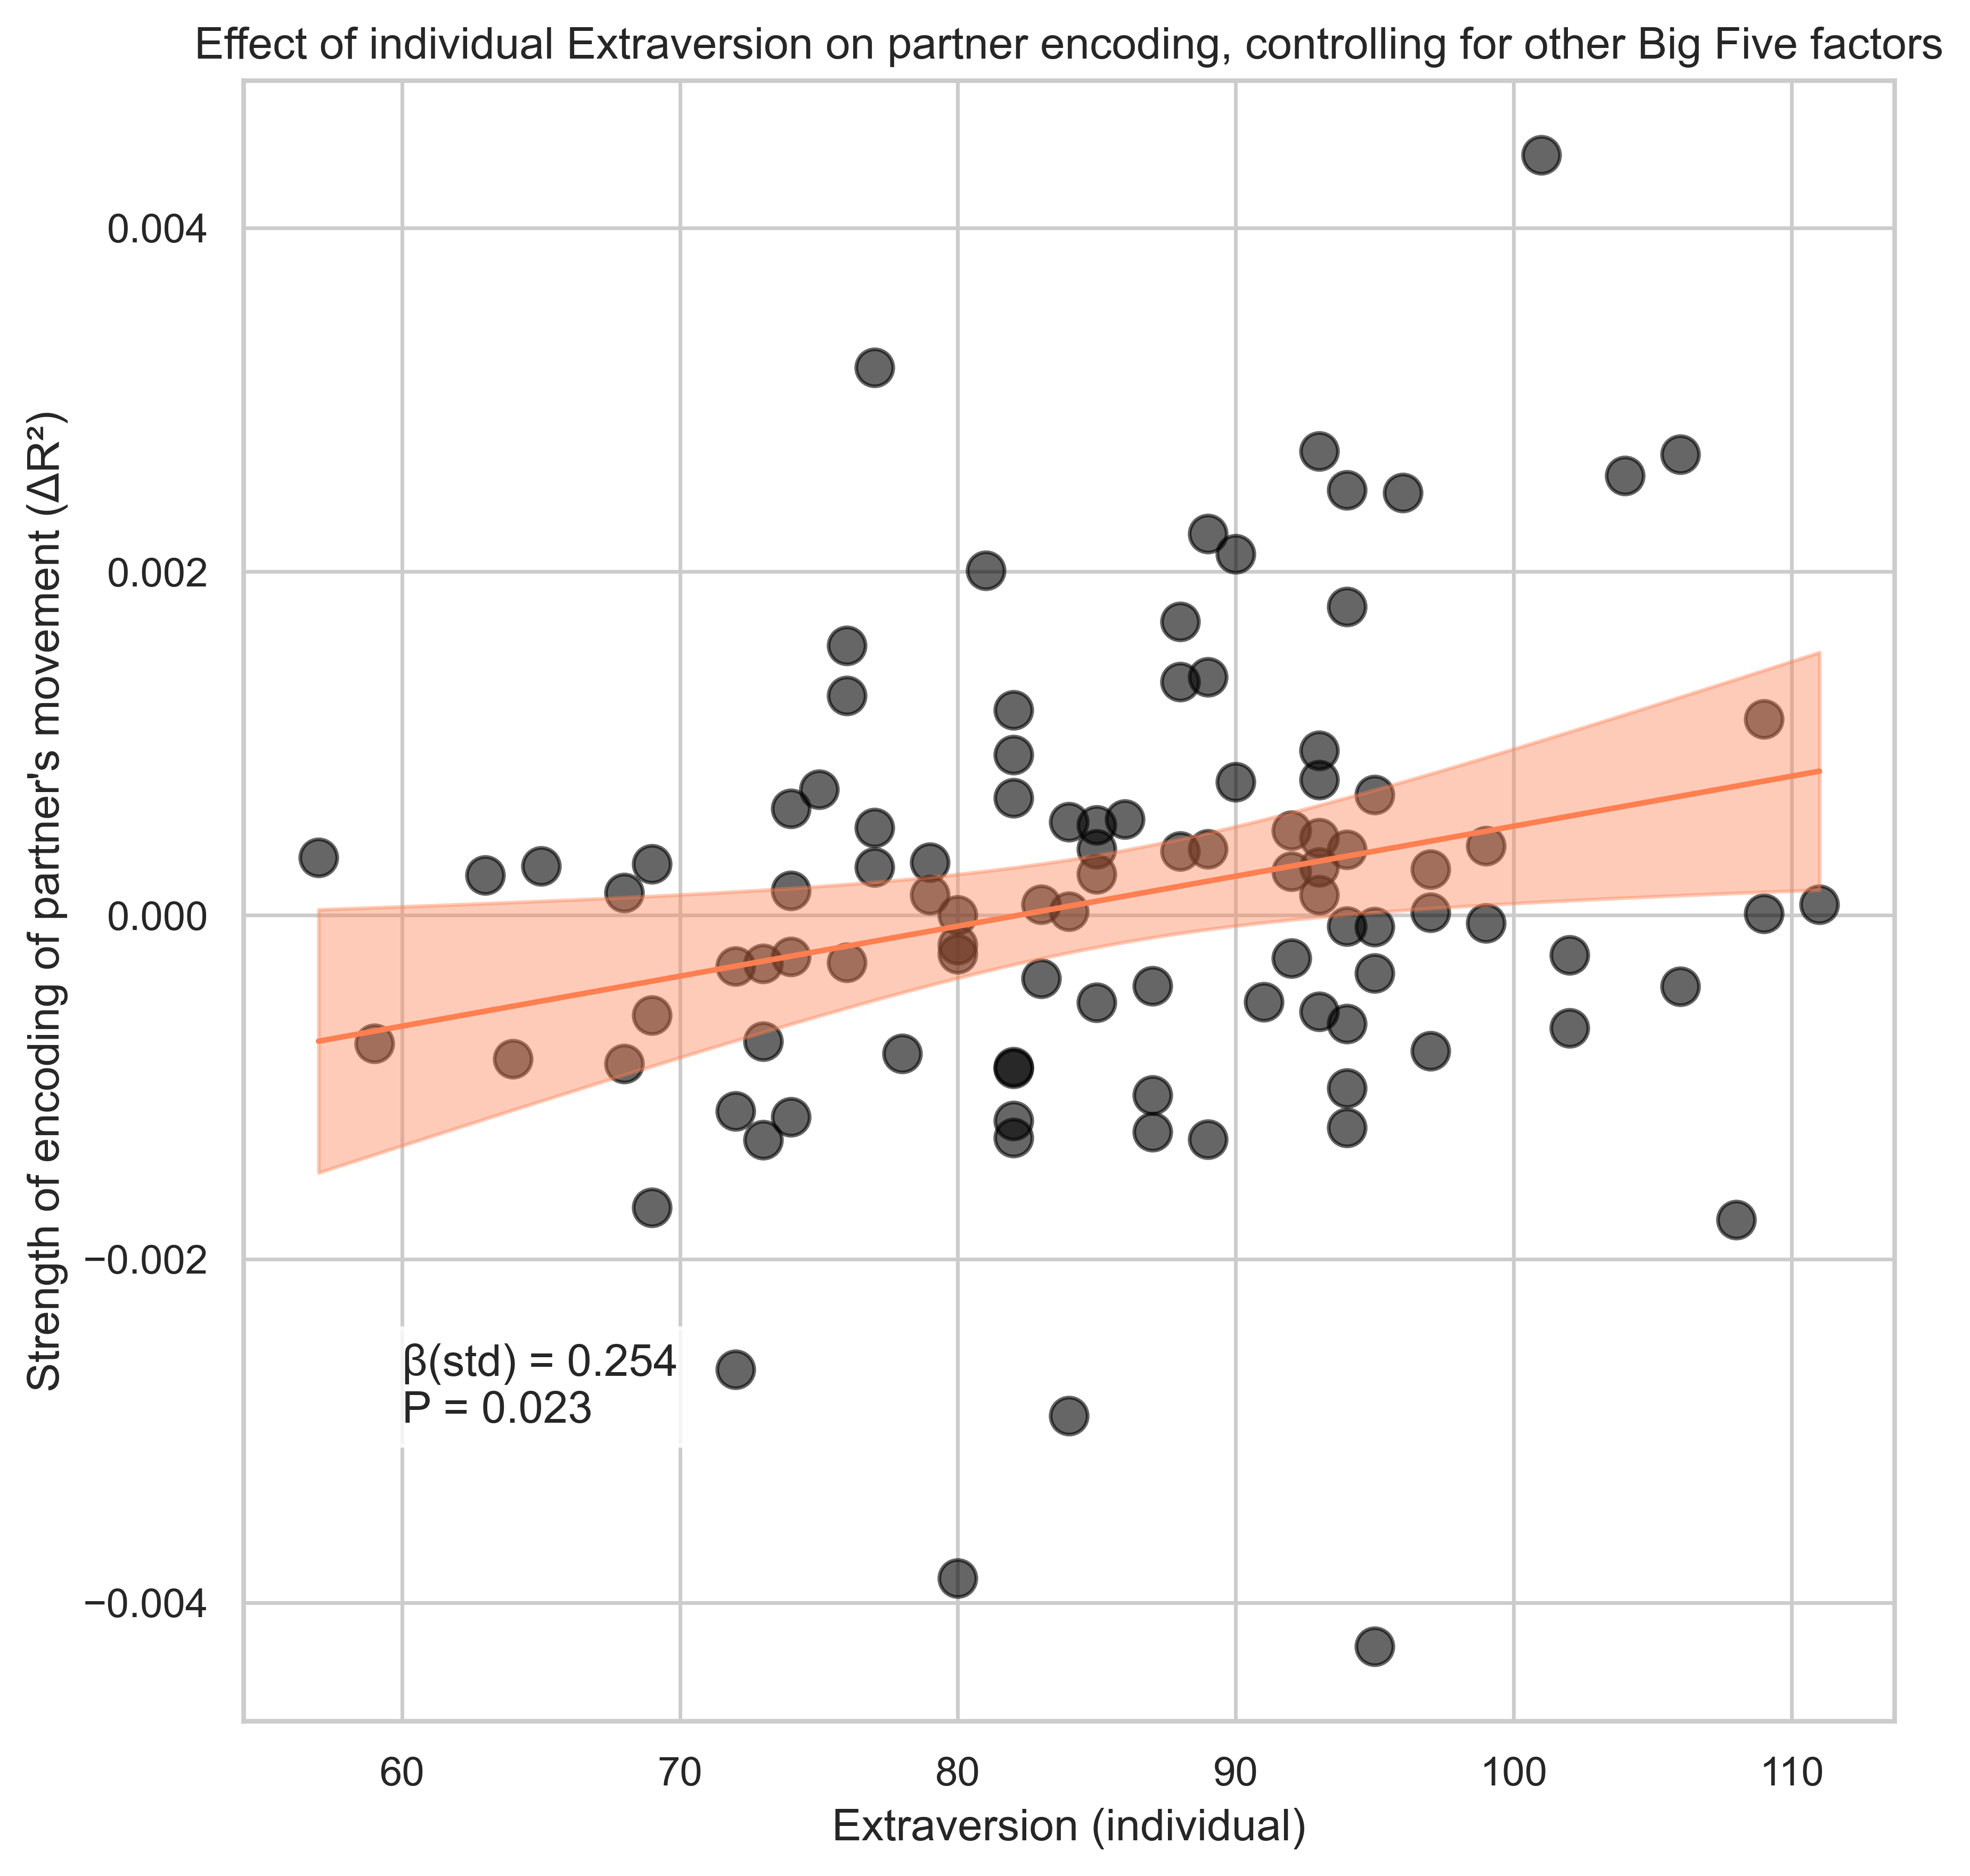

In [18]:
# Fit model
model_full = smf.mixedlm(
    formula="Vision_other ~ Extraversion + Neuroticism + Agreeableness + Conscientiousness + Openness",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=True)

# Grid (PC2, PC3 at mean)
extr_vals = np.linspace(trigger_test["Extraversion"].min(),
                       trigger_test["Extraversion"].max(), 100)

pred_df = pd.DataFrame({
    "Extraversion": extr_vals,
    "Neuroticism": trigger_test["Neuroticism"].mean(),
    "Agreeableness": trigger_test["Agreeableness"].mean(),
    "Conscientiousness": trigger_test["Conscientiousness"].mean(),
    "Openness": trigger_test["Openness"].mean()
})

# Use the original design_inf
design_info = model_full.model.data.design_info
exog = patsy.build_design_matrices([design_info], pred_df)[0]

# Fixed effects
fe_params = model_full.fe_params.values
cov_fe = model_full.cov_params().loc[
    model_full.fe_params.index,
    model_full.fe_params.index
].values

# Predictions + CI
y_hat = np.asarray(exog @ fe_params).flatten()
se = np.sqrt(np.sum(exog @ cov_fe * exog, axis=1))
ci_lower = y_hat - 1.96 * se
ci_upper = y_hat + 1.96 * se

# Plot
plt.figure(figsize=(8,8), dpi=500)
plt.scatter(trigger_test["Extraversion"], trigger_test["Vision_other"], color='black',alpha=0.6,s=100)
plt.plot(extr_vals, y_hat,color='coral')
plt.fill_between(extr_vals, ci_lower, ci_upper, alpha=0.4,color='coral')

text_block = f'β(std) = 0.254\nP = 0.023'
plt.text(60, -0.003, text_block,
            horizontalalignment='left', verticalalignment='bottom',
            bbox=dict(facecolor='white', alpha=0.8),
            fontsize=12)

plt.xlabel("Extraversion (individual)")
plt.ylabel("Strength of encoding of partner's movement (ΔR²)")
plt.title("Effect of individual Extraversion on partner encoding, controlling for other Big Five factors")
plt.show()

In [19]:
### Examining the effects of personality factors on the Self encoding

model_full = smf.mixedlm(
    formula="scale(Vision_self) ~ scale(Extraversion) + scale(Neuroticism) + scale(Agreeableness) + scale(Conscientiousness) + scale(Openness)",
    data=trigger_test,
    groups=trigger_test["pair"]
).fit(reml=True)

print(model_full.summary())

               Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  scale(Vision_self)
No. Observations:  102      Method:              REML              
No. Groups:        51       Scale:               1.0211            
Min. group size:   2        Log-Likelihood:      -150.8123         
Max. group size:   2        Converged:           Yes               
Mean group size:   2.0                                             
-------------------------------------------------------------------
                         Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------------
Intercept                 0.000    0.100  0.000 1.000 -0.196  0.196
scale(Extraversion)       0.157    0.116  1.349 0.177 -0.071  0.384
scale(Neuroticism)        0.062    0.120  0.513 0.608 -0.174  0.297
scale(Agreeableness)      0.111    0.114  0.970 0.332 -0.113  0.335
scale(Conscientiousness) -0.106    0.108 -0.987 0.324 -0.317  0

/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/Users/aldab/Library/Python/3.9/lib/python/site-packages/statsmodels/iolib/summary2.py:579: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  dat = dat.applymap(lambda x: _formatter(x, float_format))


# Exploring potential mediation

PearsonRResult(statistic=-0.31468546303715966, pvalue=0.0012763381494471633)


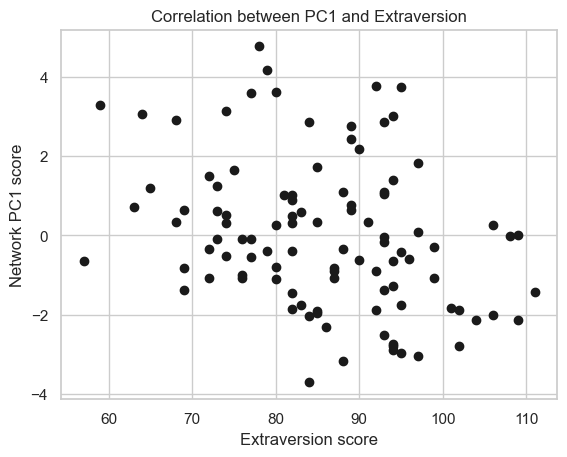

In [47]:
print(scipy.stats.pearsonr(trigger_test['Extraversion'],trigger_test['PC1']))

plt.plot(trigger_test['Extraversion'],trigger_test['PC1'],'o',color='k')
plt.title('Correlation between PC1 and Extraversion')
plt.xlabel('Extraversion score')
plt.ylabel('Network PC1 score')
plt.show()

In [ ]:
from statsmodels.stats.mediation import Mediation
from sklearn.preprocessing import StandardScaler

# Assuming 'df' is your pandas DataFrame containing:
# X: Independent variable (treatment/predictor)
# M: Mediator variable
# Y: Outcome variable
# Group: The clustering variable for your random intercepts

# ---------------------------------------------------------
# Step 1: Specify the Mediator Model
# M is predicted by X, accounting for random effects
# ---------------------------------------------------------
scaler = StandardScaler()
trigger_test_scaled = trigger_test.copy()
trigger_test_scaled[['Vision_other','PC1','Extraversion']] = scaler.fit_transform(trigger_test[['Vision_other','PC1','Extraversion']])

mediator_model = smf.ols("Extraversion ~ PC1", trigger_test_scaled)

# ---------------------------------------------------------
# Step 2: Specify the Outcome Model (Remains LMM)
# Y is predicted by M and X, accounting for random effects
# ---------------------------------------------------------
outcome_model = smf.mixedlm("Vision_other ~ Extraversion + PC1", trigger_test_scaled, groups=trigger_test_scaled["pair"])

# ---------------------------------------------------------
# Step 3: Run the Causal Mediation Analysis
# ---------------------------------------------------------
med = Mediation(outcome_model, mediator_model, exposure='PC1', mediator='Extraversion')
med_result = med.fit()

print(med_result.summary())

                          Estimate  Lower CI bound  Upper CI bound  P-value
ACME (control)           -0.052671       -0.156590        0.010979    0.148
ACME (treated)           -0.052671       -0.156590        0.010979    0.148
ADE (control)            -0.143947       -0.336539        0.056210    0.152
ADE (treated)            -0.143947       -0.336539        0.056210    0.152
Total effect             -0.196618       -0.389963       -0.007538    0.042
Prop. mediated (control)  0.235300       -0.324618        1.642970    0.186
Prop. mediated (treated)  0.235300       -0.324618        1.642970    0.186
ACME (average)           -0.052671       -0.156590        0.010979    0.148
ADE (average)            -0.143947       -0.336539        0.056210    0.152
Prop. mediated (average)  0.235300       -0.324618        1.642970    0.186
